# PBMC 3k single-cell RNA-seq analysis (Scanpy)

**Goal:** go from raw counts to annotated cell types, and check how robust the result is.

Steps: QC -> doublet detection -> normalization -> dimensionality reduction -> clustering
(several resolutions) -> marker genes -> annotation -> differential expression -> stability check.

Data: 10x Genomics PBMC 3k (~2,700 peripheral blood mononuclear cells), downloaded by Scanpy.

In [1]:
# Run once (Colab, or local if packages are missing):
!pip install -q scanpy igraph scikit-learn scikit-image
# Note: do NOT install the separate "scrublet" package (it needs annoy, which fails to build on Windows).
# Recent Scanpy versions include Scrublet themselves; scikit-image is the only extra it needs.

  You can safely remove it manually.

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score

SEED = 0
np.random.seed(SEED)
sc.settings.verbosity = 2
sc.settings.set_figure_params(dpi=100, facecolor="white", frameon=False)
os.makedirs("figures", exist_ok=True)
sc.settings.figdir = "figures"
print("scanpy", sc.__version__)

scanpy 1.11.5


C:\Users\DELL\AppData\Local\Temp\ipykernel_20756\2377070996.py:14: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("scanpy", sc.__version__)


## 1. Load data

In [3]:
adata = sc.datasets.pbmc3k()          # raw counts: cells x genes
adata.var_names_make_unique()
print(adata)

try downloading from url
https://falexwolf.de/data/pbmc3k_raw.h5ad
... this may take a while but only happens once


d:\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 5.58M/5.58M [00:04<00:00, 1.27MB/s]


AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'


## 2. Quality control
Low gene counts suggest empty droplets; very high counts suggest doublets;
a high fraction of mitochondrial reads suggests dying or broken cells.

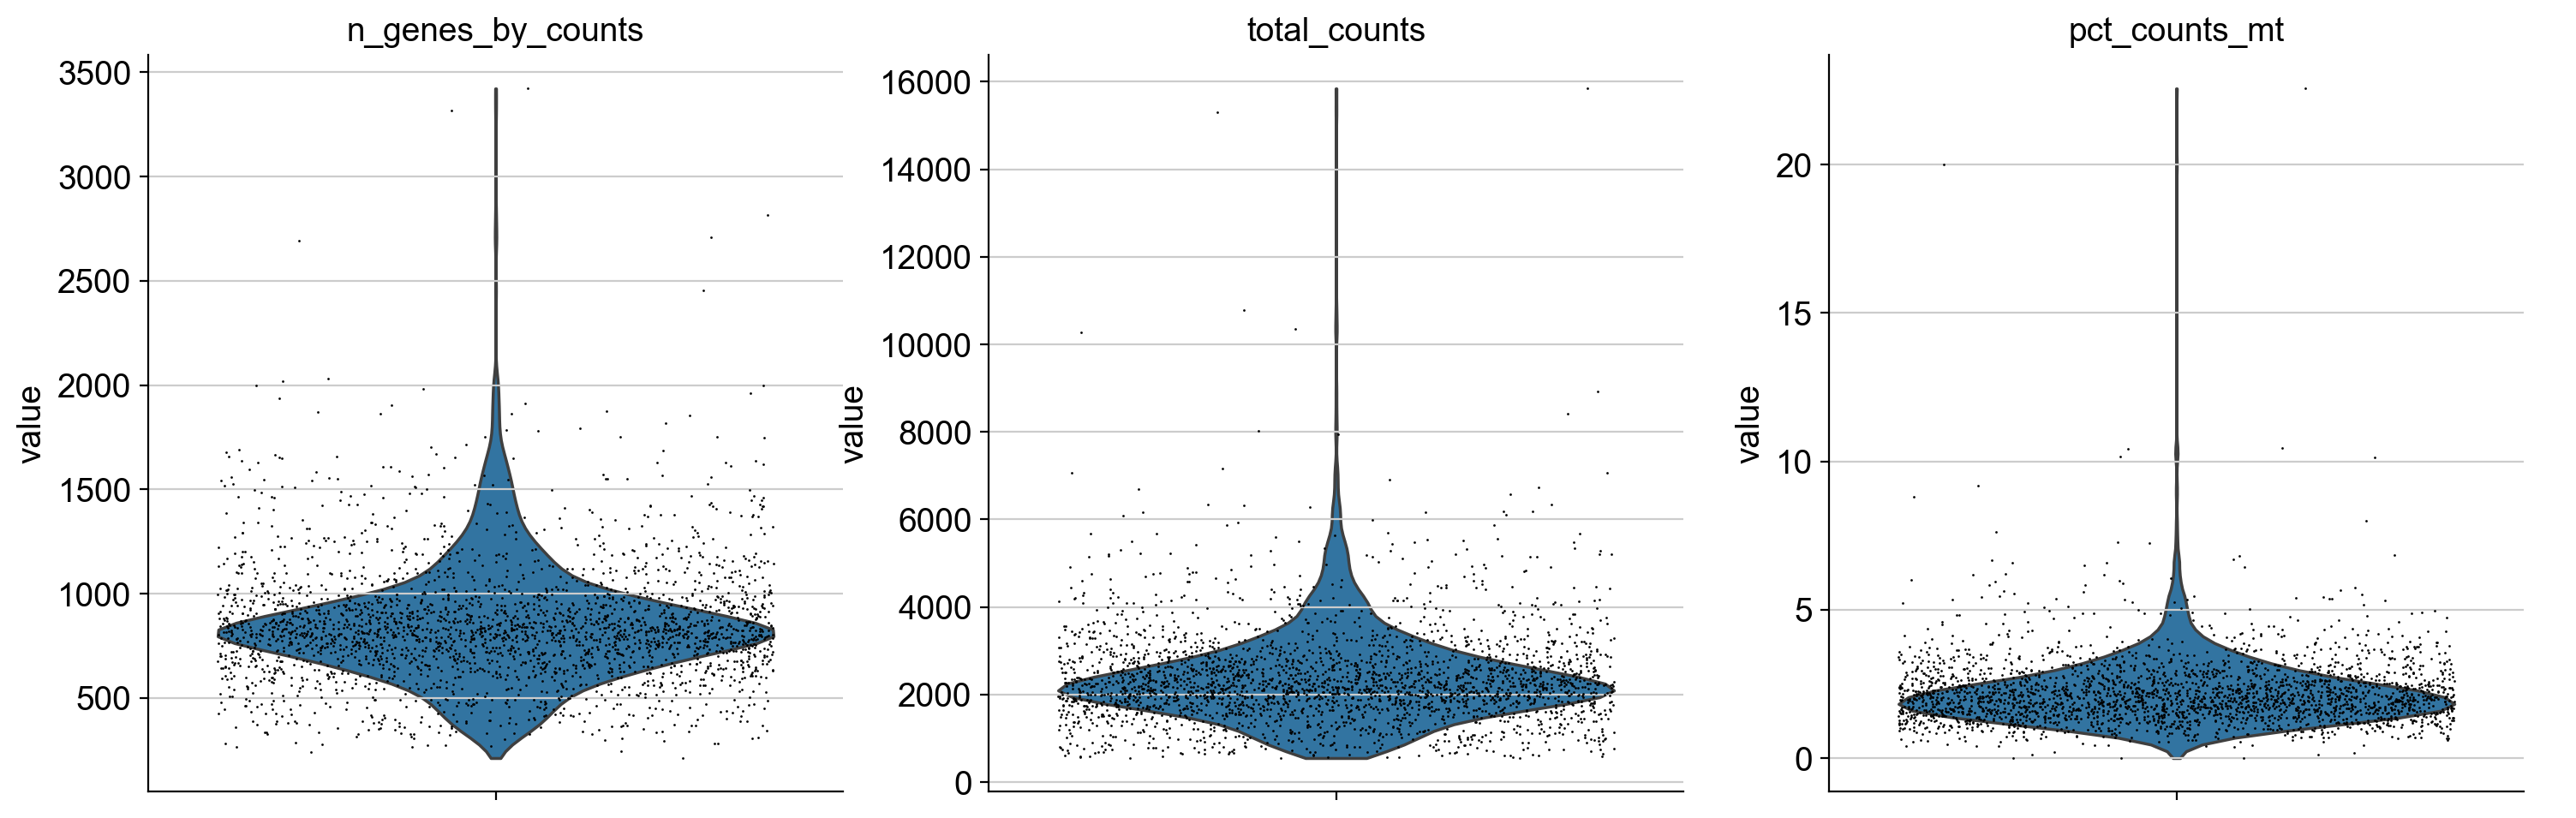

In [4]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
n0 = adata.n_obs

sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
             jitter=0.4, multi_panel=True, save="_qc_before.png", show=True)

In [5]:
# Thresholds: look at the violin plots above and justify your own choices.
MIN_GENES, MAX_GENES, MAX_MT = 200, 2500, 5.0

sc.pp.filter_cells(adata, min_genes=MIN_GENES)
sc.pp.filter_genes(adata, min_cells=3)
adata = adata[(adata.obs["n_genes_by_counts"] < MAX_GENES) & (adata.obs["pct_counts_mt"] < MAX_MT)].copy()
print(f"cells: {n0} -> {adata.n_obs}   genes: {adata.n_vars}")

filtered out 19024 genes that are detected in less than 3 cells
cells: 2700 -> 2638   genes: 13714


## 3. Doublet detection (Scrublet)
Run on raw counts, before normalization.

In [6]:
try:
    sc.pp.scrublet(adata)
    print(adata.obs["predicted_doublet"].value_counts())
    n_before_doublets = adata.n_obs
    adata = adata[~adata.obs["predicted_doublet"]].copy()
    print(f"removed {n_before_doublets - adata.n_obs} predicted doublets; {adata.n_obs} cells remain")
except ImportError:
    print("scrublet is not installed: doublet detection SKIPPED. "
          "Say so in your README and do not claim this step.")

Running Scrublet
filtered out 58 genes that are detected in less than 3 cells
normalizing counts per cell
    finished (0:00:04)
extracting highly variable genes
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
Embedding transcriptomes using PCA...
    using data matrix X directly
Automatically set threshold at doublet score = 0.24
Detected doublet rate = 1.6%
Estimated detectable doublet fraction = 38.3%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 4.3%
    Scrublet finished (0:00:13)
predicted_doublet
False    2595
True       43
Name: count, dtype: int64
removed 43 predicted doublets; 2595 cells remain


## 4. Normalization, feature selection, PCA, UMAP

normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
highly variable genes: 1848


d:\Python\Python311\Lib\functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


computing PCA
    with n_comps=50
    finished (0:00:02)


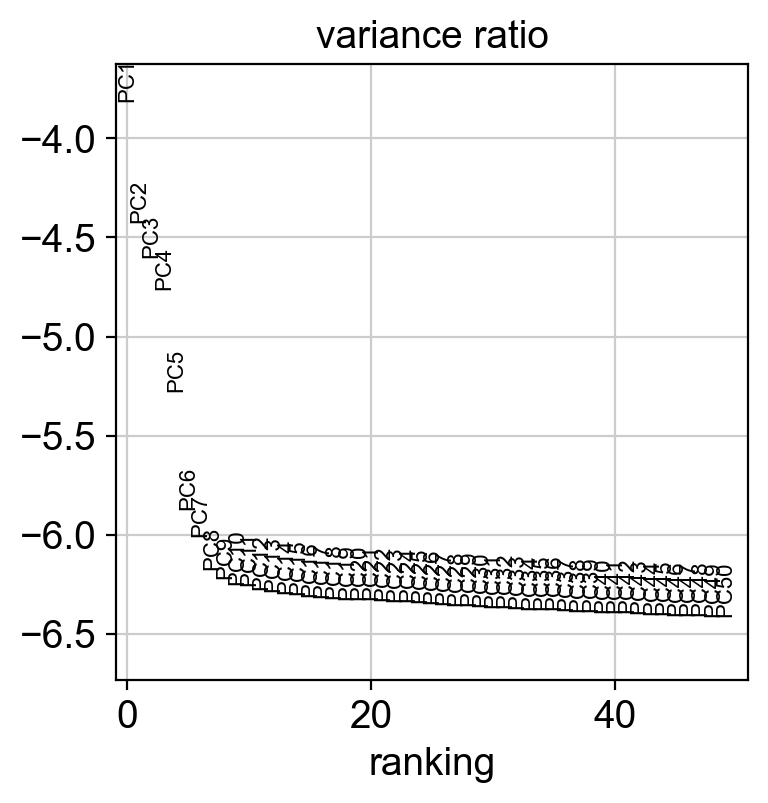

In [7]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata                       # keep full log-normalized matrix for plotting markers

sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
print("highly variable genes:", int(adata.var["highly_variable"].sum()))
adata = adata[:, adata.var["highly_variable"]].copy()

sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, svd_solver="arpack", random_state=SEED)
sc.pl.pca_variance_ratio(adata, log=True, n_pcs=50, save="_pca_variance.png")

In [8]:
N_PCS = 10                              # pick from the elbow plot above and justify it
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=N_PCS, random_state=SEED)
sc.tl.umap(adata, random_state=SEED)

computing neighbors
    using 'X_pca' with n_pcs = 10
    finished (0:00:29)
computing UMAP
    finished (0:00:04)


## 5. Clustering at several resolutions
Higher resolution gives more, smaller clusters. Compare them instead of trusting one default.

running Leiden clustering
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
{0.2: 6, 0.5: 9, 0.8: 11, 1.2: 15}


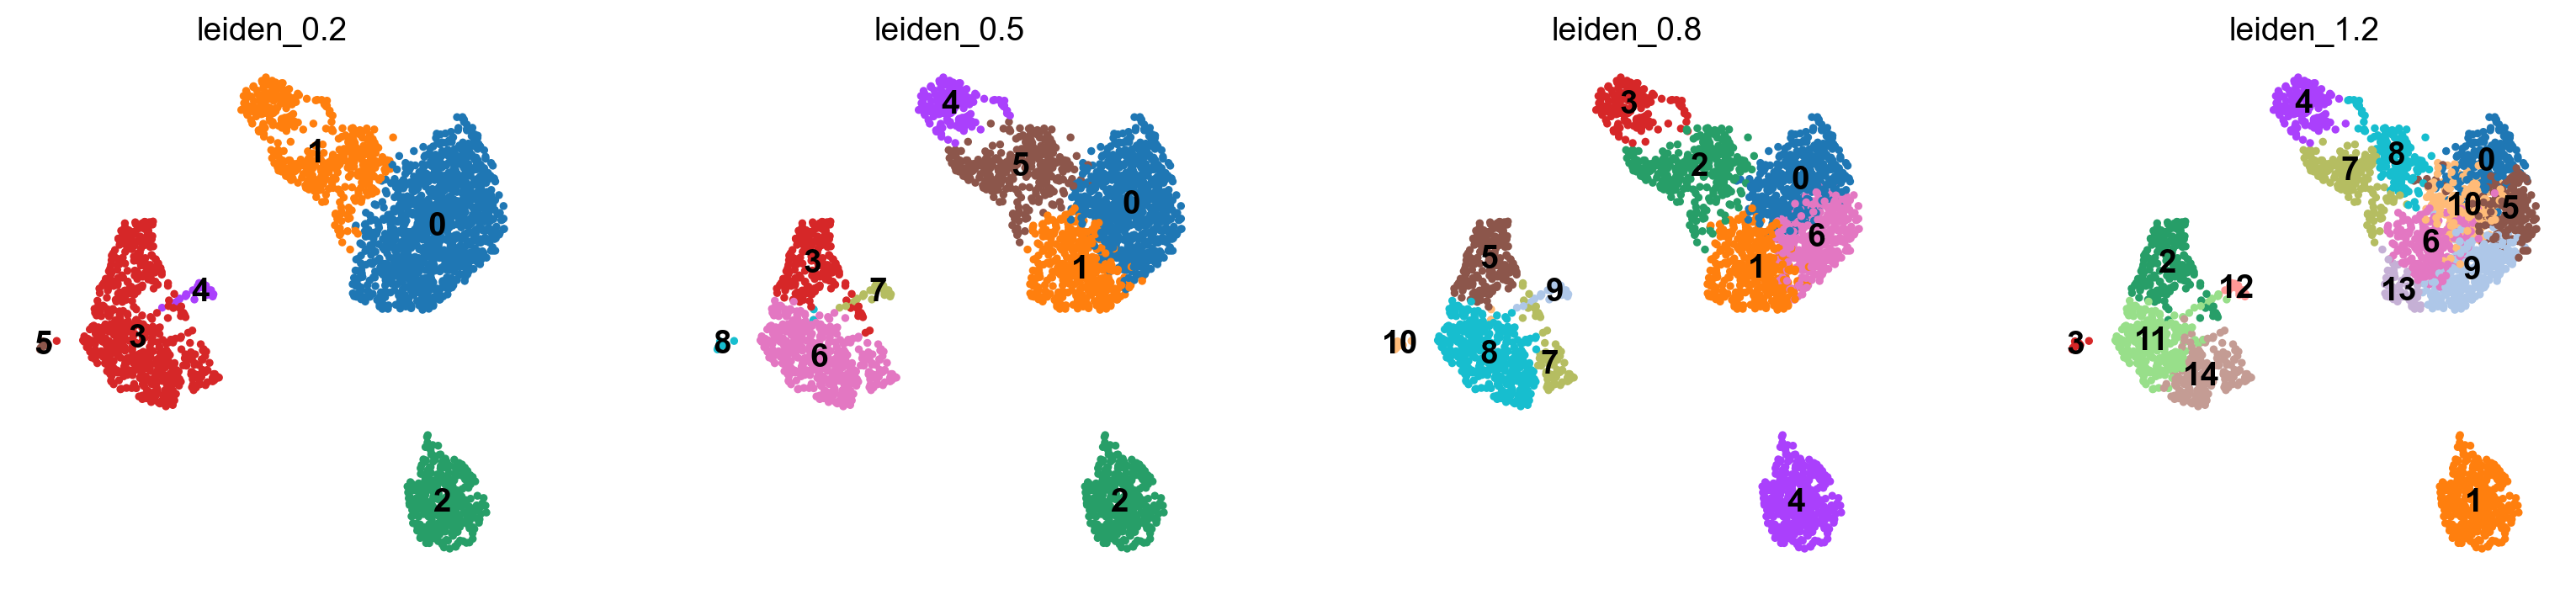

In [9]:
RESOLUTIONS = [0.2, 0.5, 0.8, 1.2]
for r in RESOLUTIONS:
    sc.tl.leiden(adata, resolution=r, key_added=f"leiden_{r}", random_state=SEED,
                 flavor="igraph", n_iterations=2, directed=False)
print({r: adata.obs[f"leiden_{r}"].nunique() for r in RESOLUTIONS})

sc.pl.umap(adata, color=[f"leiden_{r}" for r in RESOLUTIONS], legend_loc="on data",
           save="_resolutions.png")

In [10]:
CHOSEN = 0.5                            # choose after looking at the plots and marker genes
adata.obs["cluster"] = adata.obs[f"leiden_{CHOSEN}"]

## 6. Marker genes and annotation

ranking genes
    finished (0:00:13)


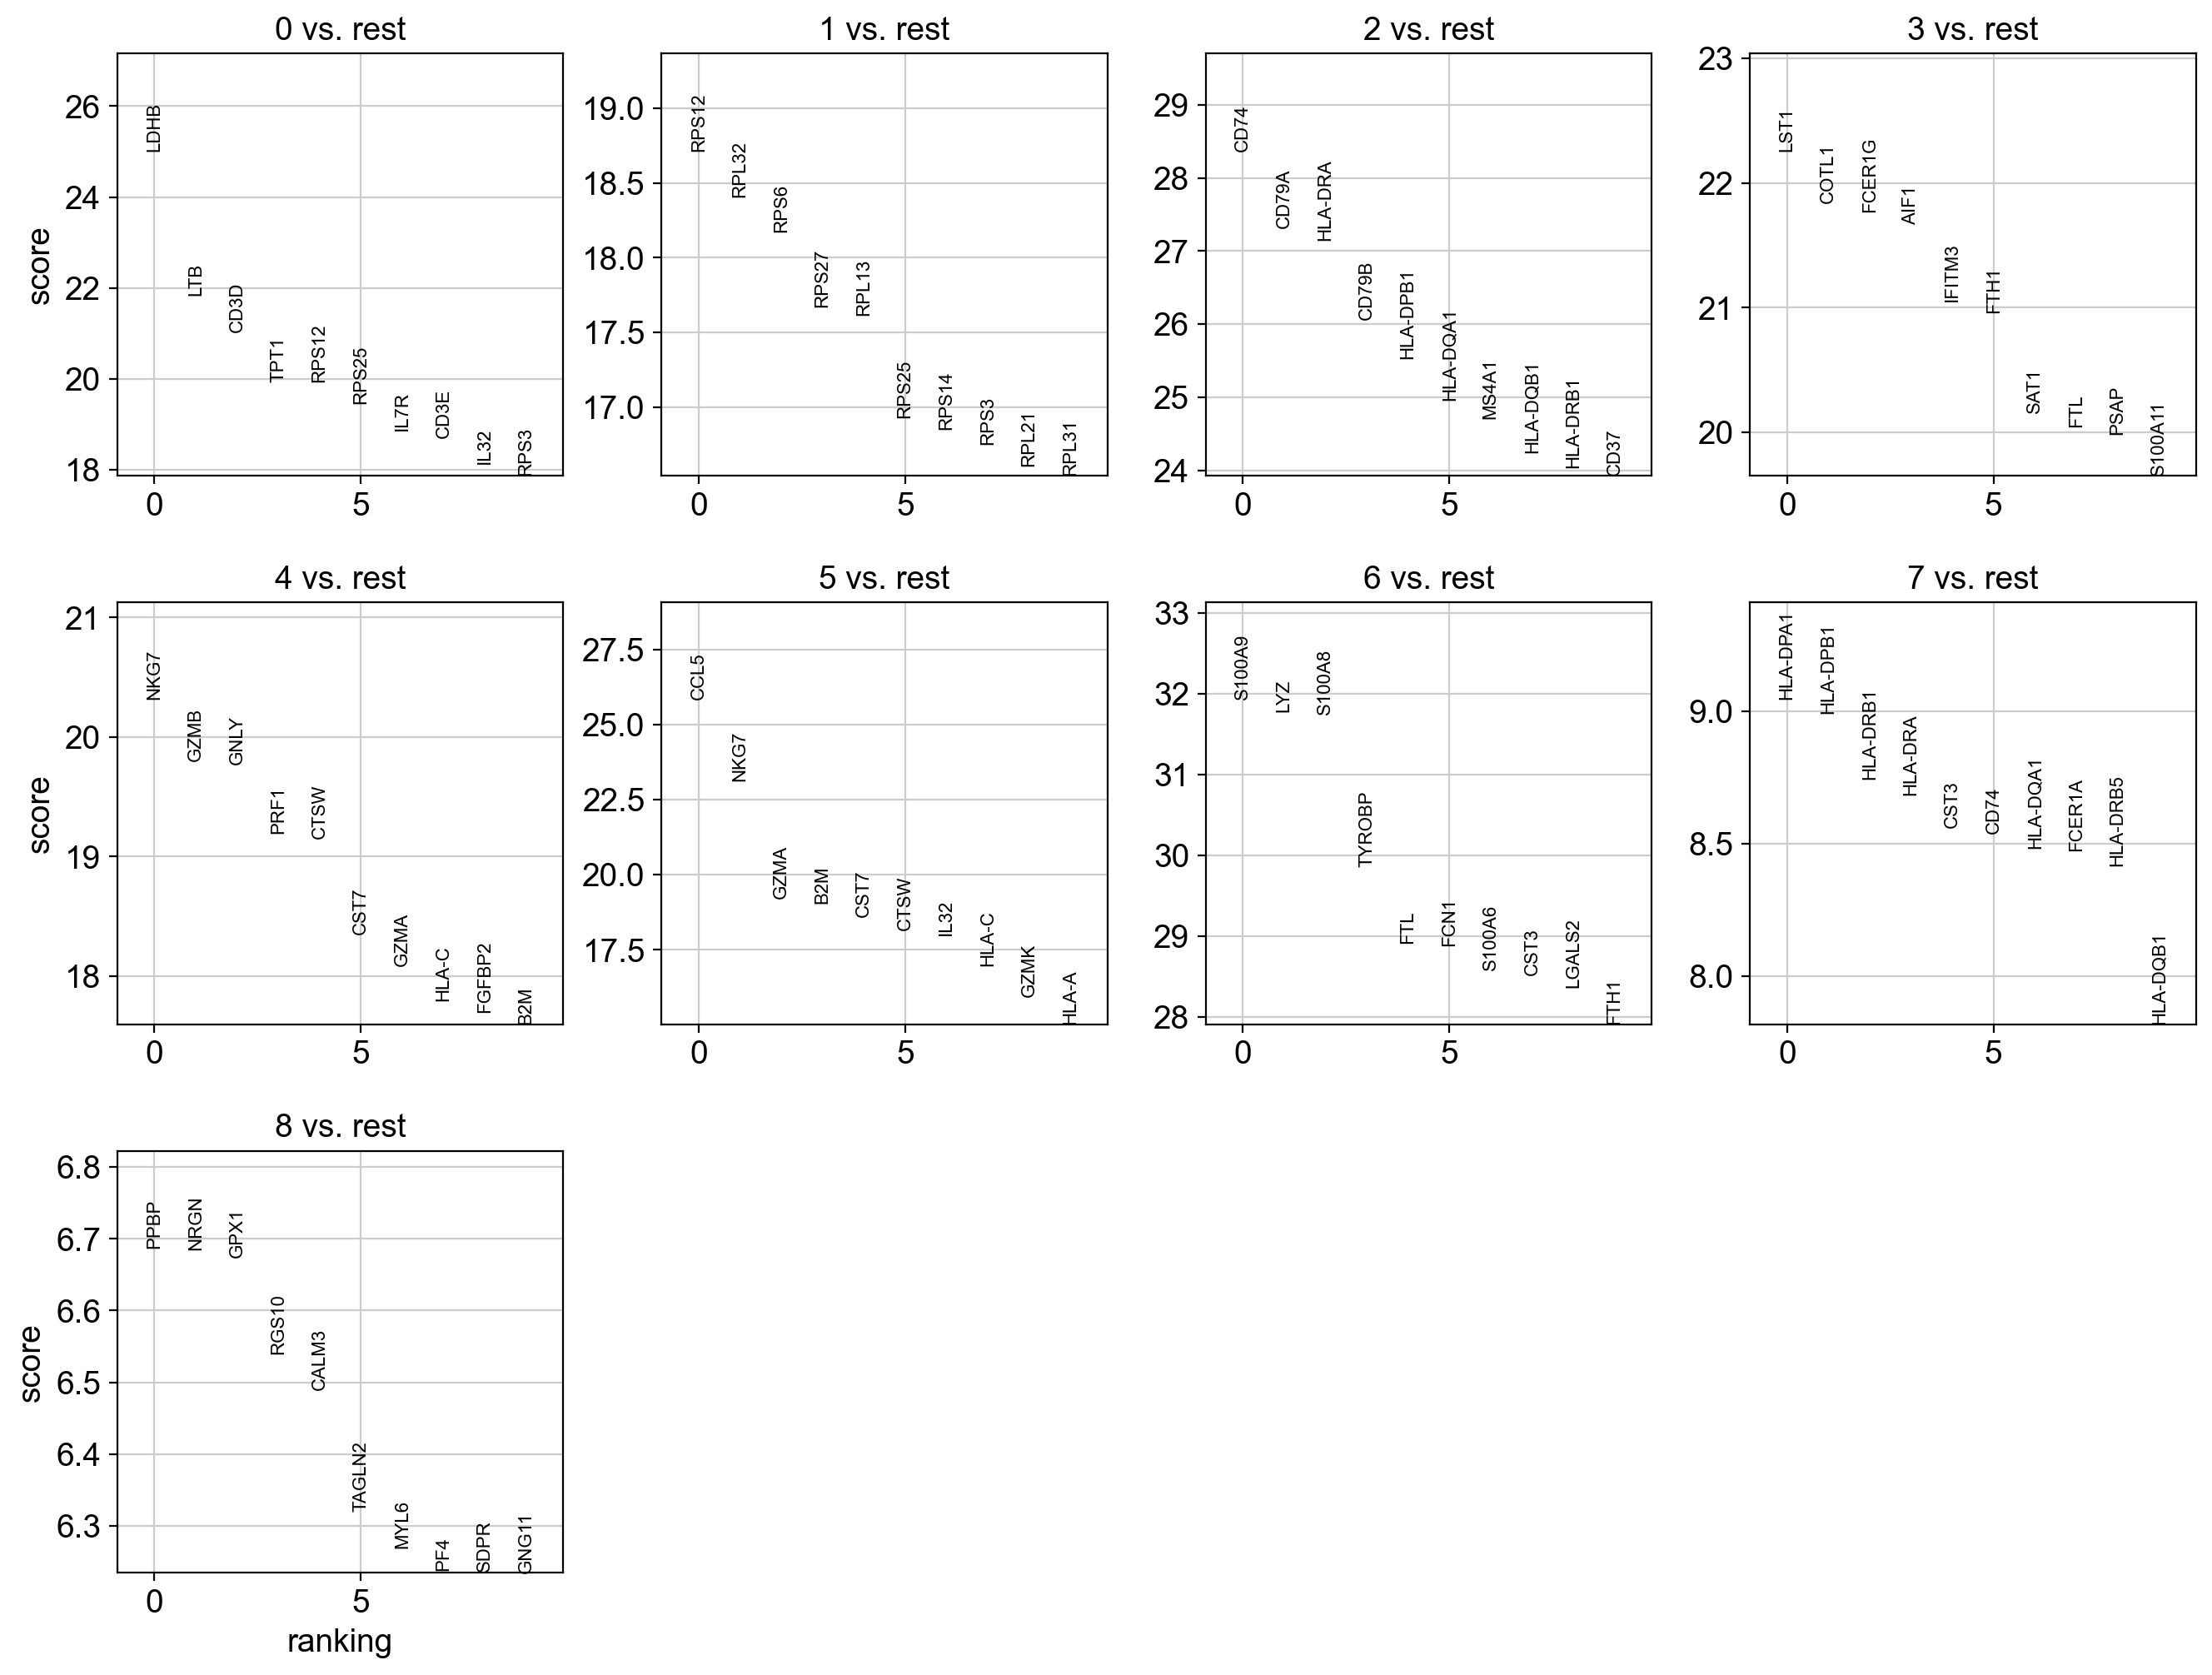

       0      1         2       3      4      5       6         7       8
0   LDHB  RPS12      CD74    LST1   NKG7   CCL5  S100A9  HLA-DPA1    PPBP
1    LTB  RPL32     CD79A   COTL1   GZMB   NKG7     LYZ  HLA-DPB1    NRGN
2   CD3D   RPS6   HLA-DRA  FCER1G   GNLY   GZMA  S100A8  HLA-DRB1    GPX1
3   TPT1  RPS27     CD79B    AIF1   PRF1    B2M  TYROBP   HLA-DRA   RGS10
4  RPS12  RPL13  HLA-DPB1  IFITM3   CTSW   CST7     FTL      CST3   CALM3
5  RPS25  RPS25  HLA-DQA1    FTH1   CST7   CTSW    FCN1      CD74  TAGLN2
6   IL7R  RPS14     MS4A1    SAT1   GZMA   IL32  S100A6  HLA-DQA1    MYL6
7   CD3E   RPS3  HLA-DQB1     FTL  HLA-C  HLA-C    CST3    FCER1A     PF4


In [11]:
sc.tl.rank_genes_groups(adata, "cluster", method="wilcoxon", use_raw=True)
sc.pl.rank_genes_groups(adata, n_genes=10, sharey=False, save="_markers.png")

top = pd.DataFrame(adata.uns["rank_genes_groups"]["names"]).head(8)
print(top)

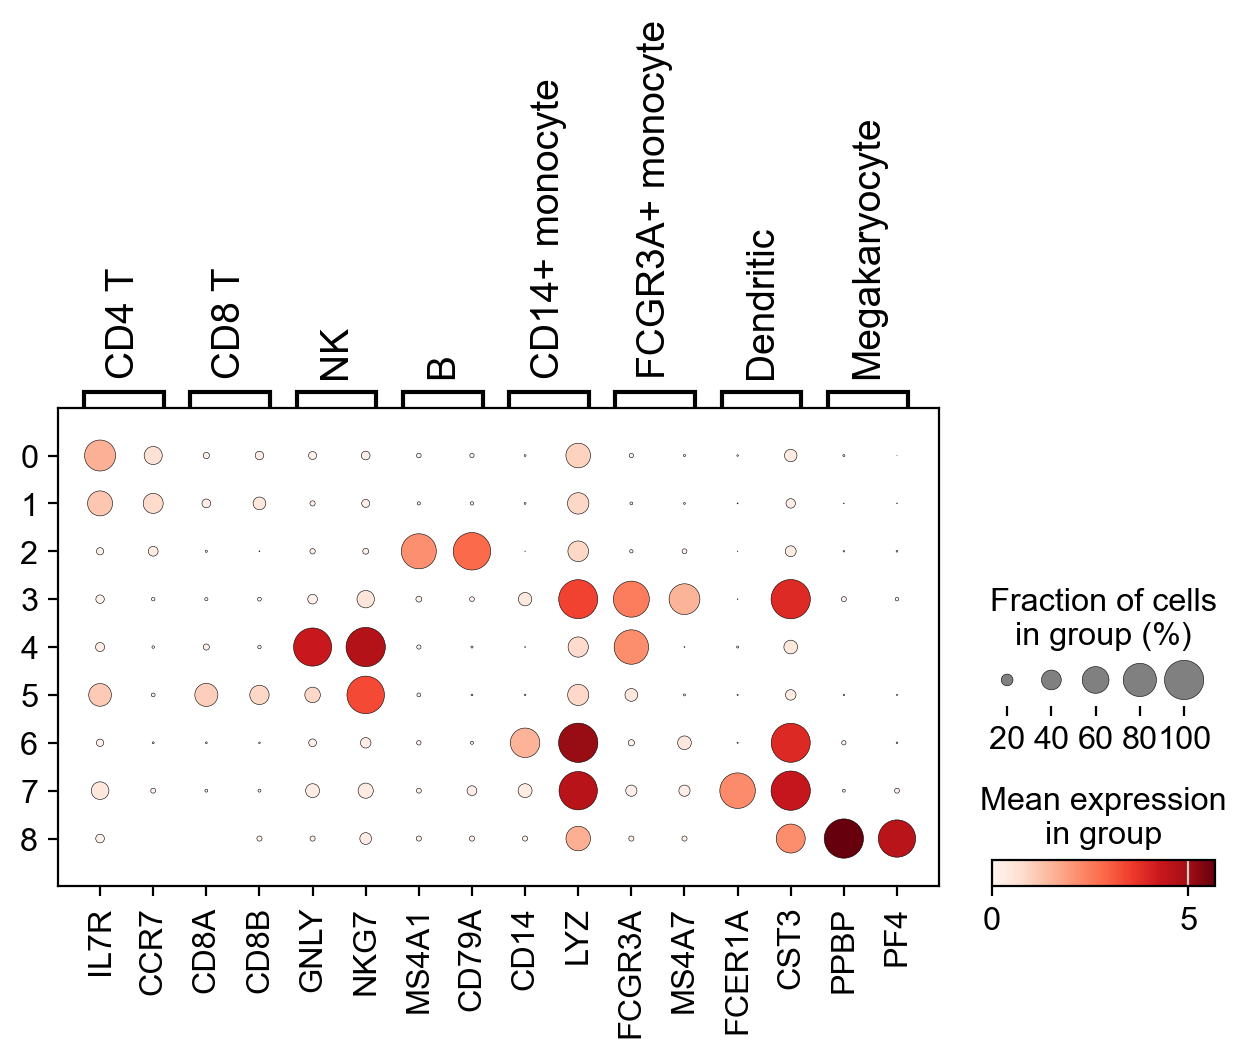

In [12]:
marker_dict = {
    "CD4 T":            ["IL7R", "CCR7"],
    "CD8 T":            ["CD8A", "CD8B"],
    "NK":               ["GNLY", "NKG7"],
    "B":                ["MS4A1", "CD79A"],
    "CD14+ monocyte":   ["CD14", "LYZ"],
    "FCGR3A+ monocyte": ["FCGR3A", "MS4A7"],
    "Dendritic":        ["FCER1A", "CST3"],
    "Megakaryocyte":    ["PPBP", "PF4"],
}
marker_dict = {k: [g for g in v if g in adata.raw.var_names] for k, v in marker_dict.items()}
sc.pl.dotplot(adata, marker_dict, groupby="cluster", use_raw=True, save="_marker_dotplot.png")

In [13]:
# Suggest a label per cluster (mean marker expression), then CONFIRM by eye on the dotplot.
raw_df = pd.DataFrame(adata.raw.X.toarray() if hasattr(adata.raw.X, "toarray") else adata.raw.X,
                      index=adata.obs_names, columns=adata.raw.var_names)
raw_df["cluster"] = adata.obs["cluster"].values
cluster_means = raw_df.groupby("cluster", observed=True).mean()
z = (cluster_means - cluster_means.mean()) / cluster_means.std().replace(0, 1)
suggest = {c: max(marker_dict, key=lambda t: z.loc[c, marker_dict[t]].mean()) for c in z.index}
print(suggest)

{'0': 'CD4 T', '1': 'CD4 T', '2': 'B', '3': 'FCGR3A+ monocyte', '4': 'NK', '5': 'CD8 T', '6': 'CD14+ monocyte', '7': 'Dendritic', '8': 'Megakaryocyte'}


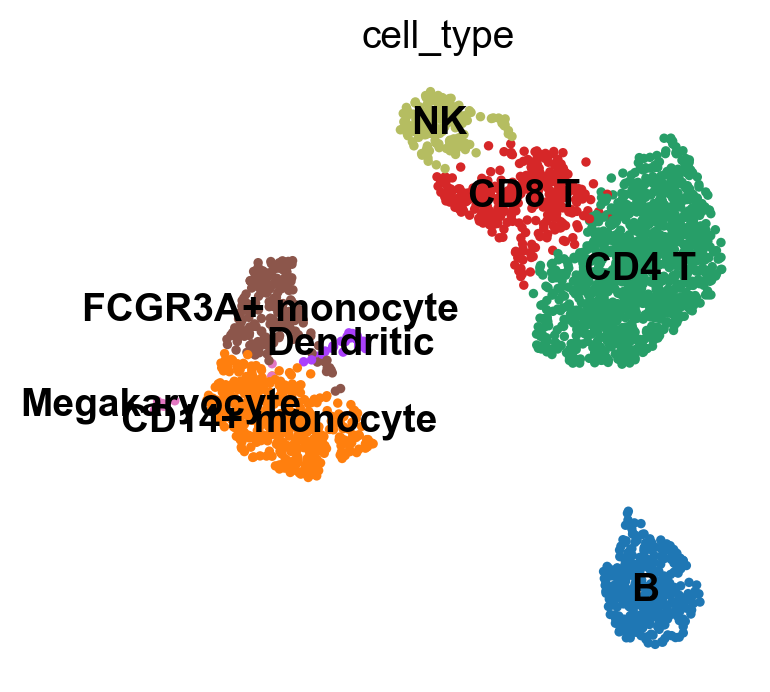

In [14]:
# Edit this mapping after checking the dotplot. Do not accept the suggestion blindly.
cluster_to_type = dict(suggest)
adata.obs["cell_type"] = adata.obs["cluster"].map(cluster_to_type).astype("category")
sc.pl.umap(adata, color="cell_type", legend_loc="on data", save="_cell_types.png")

cell_type
CD4 T               43.6
CD14+ monocyte      16.2
B                   12.6
CD8 T               12.1
FCGR3A+ monocyte     7.7
NK                   6.0
Dendritic            1.2
Megakaryocyte        0.6
Name: proportion, dtype: float64


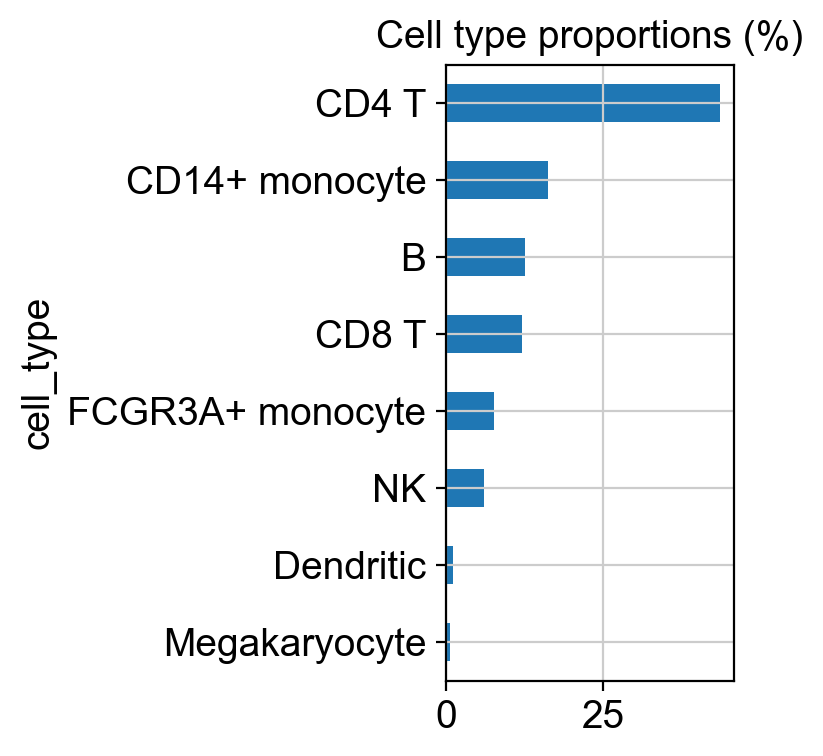

In [15]:
props = adata.obs["cell_type"].value_counts(normalize=True).mul(100).round(1)
print(props)
props.sort_values().plot.barh(title="Cell type proportions (%)")
plt.tight_layout(); plt.savefig("figures/cell_type_proportions.png", dpi=150); plt.show()

## 7. Differential expression between two related groups
Example: the two monocyte populations. Interpret the top genes biologically in your README.

In [16]:
if {"CD14+ monocyte", "FCGR3A+ monocyte"} <= set(adata.obs["cell_type"].unique()):
    sc.tl.rank_genes_groups(adata, "cell_type", groups=["FCGR3A+ monocyte"],
                            reference="CD14+ monocyte", method="wilcoxon", use_raw=True,
                            key_added="de_monocytes")
    de = sc.get.rank_genes_groups_df(adata, group="FCGR3A+ monocyte", key="de_monocytes")
    print(de.head(15))
    de.to_csv("figures/de_monocytes.csv", index=False)
else:
    print("Both monocyte labels not found. Pick two other related groups.")

ranking genes
    finished (0:00:00)
            names     scores  logfoldchanges         pvals     pvals_adj
0          FCGR3A  17.377573        6.126705  1.220090e-67  4.183079e-64
1          IFITM2  16.735552        2.927802  7.218410e-63  1.979865e-59
2           RPS19  15.534693        1.177387  2.020388e-54  4.617934e-51
3            LST1  14.017842        1.281467  1.212459e-44  2.078457e-41
4            RHOC  13.878490        4.014802  8.552617e-44  1.303229e-40
5          FCER1G  13.224280        1.260912  6.354286e-40  7.922061e-37
6           COTL1  13.166675        1.064569  1.364770e-39  1.559705e-36
7             B2M  11.905581        0.627979  1.106900e-32  1.167695e-29
8          IFITM3  11.825029        2.169485  2.898013e-32  2.838810e-29
9            ABI3  11.190419        2.892671  4.542826e-29  3.893770e-26
10           AIF1  11.090746        0.946900  1.391234e-28  1.122316e-25
11          MS4A7  10.712370        2.685476  8.905287e-27  6.427742e-24
12          TI

## 8. Stability check
Re-run neighbors + Leiden with different random seeds and compare to the reference
clustering with the adjusted Rand index (1.0 = identical).

In [17]:
ref = adata.obs["cluster"].values
rows = []
for s in range(1, 6):
    sc.pp.neighbors(adata, n_neighbors=10, n_pcs=N_PCS, random_state=s, key_added=f"nn_{s}")
    sc.tl.leiden(adata, resolution=CHOSEN, random_state=s, neighbors_key=f"nn_{s}",
                 key_added=f"leiden_seed_{s}", flavor="igraph", n_iterations=2, directed=False)
    rows.append({"seed": s,
                 "n_clusters": adata.obs[f"leiden_seed_{s}"].nunique(),
                 "ARI_vs_reference": round(adjusted_rand_score(ref, adata.obs[f"leiden_seed_{s}"]), 3)})
stability = pd.DataFrame(rows)
print(stability)
stability.to_csv("figures/stability.csv", index=False)

computing neighbors
    using 'X_pca' with n_pcs = 10
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 10
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 10
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 10
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 10
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
   seed  n_clusters  ARI_vs_reference
0     1           9             0.931
1     2           9             0.763
2     3           9             0.783
3     4           9             0.785
4     5           9             0.787


## 9. Save

In [18]:
adata.write("pbmc3k_annotated.h5ad")
print("done")

done
